# 02 - ClinVar Structural Variant Deep Exploration
**Project**: AI-Based Structural Variant Prioritization from Long-Read Sequencing Using Explainable Machine Learning  

## Objective
Analyze ClinVar structural variants (>= 50 bp):
- Clinical significance label distribution and imbalance
- SV types, lengths, and chromosome distributions
- Gene and phenotype representations
- Missing value profiling
- VUS & conflicting interpretation quantification and handling strategy


In [1]:
import os

def resolve_path(p):
    for candidate in [p, os.path.join("..", p), os.path.join("data", p), os.path.join("..", "data", p)]:
        if os.path.exists(candidate):
            return candidate
    return p

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data_path = resolve_path("processed/clinvar_sv_cleaned.csv.gz")
df_cv = pd.read_csv(data_path)
print(f"Loaded {len(df_cv):,} ClinVar SVs from {data_path}.")
df_cv.head()


Loaded 101,891 ClinVar SVs from processed/clinvar_sv_cleaned.csv.gz.


C:\Users\waibhav\AppData\Local\Temp\ipykernel_29784\3902783972.py:15: DtypeWarning: Columns (15) have mixed types. Specify dtype option on import or set low_memory=False.
  df_cv = pd.read_csv(data_path)


,allele_id,variation_id,name,type,gene_id,gene_symbol,clinsig,clinsig_simple,review_status,phenotypes,assembly,chrom,start,stop,length,dbvar_id,rs_id,origin
0,15064,25,NM_015600.4(ABHD12):c.-6898_191+7002delinsCC,Indel,26090,ABHD12,Pathogenic,1,no assertion criteria provided,PHARC syndrome,GRCh37,20,25364147,25378237,14091,nsv1067853,NaN,germline
1,15064,25,NM_015600.4(ABHD12):c.-6898_191+7002delinsCC,Indel,26090,ABHD12,Pathogenic,1,no assertion criteria provided,PHARC syndrome,GRCh38,20,25383511,25397601,14091,nsv1067853,NaN,germline
2,15138,99,NM_000355.4(TCN2):c.940+303_1106+746delinsCTGG,Indel,6948,TCN2,Pathogenic,1,no assertion criteria provided,Transcobalamin II deficiency,GRCh37,22,31012077,31014228,2152,NaN,NaN,germline
3,15138,99,NM_000355.4(TCN2):c.940+303_1106+746delinsCTGG,Indel,6948,TCN2,Pathogenic,1,no assertion criteria provided,Transcobalamin II deficiency,GRCh38,22,30616090,30618241,2152,NaN,NaN,germline
4,15213,174,NC_000010.11:g.(124404664_124404669)_(12440473...,Deletion,4942,OAT,Pathogenic,1,no assertion criteria provided,Ornithine aminotransferase deficiency,GRCh37,10,126093233,126094310,1078,nsv1197582,NaN,germline


## 1. Clinical Significance Label Breakdown

In [2]:
def categorize_clinsig(cln):
    c = str(cln).lower()
    if "pathogenic/likely pathogenic" in c:
        return "Pathogenic/Likely Pathogenic"
    elif "pathogenic" in c and "likely" not in c and "conflict" not in c:
        return "Pathogenic"
    elif "likely pathogenic" in c and "conflict" not in c:
        return "Likely Pathogenic"
    elif "benign/likely benign" in c:
        return "Benign/Likely Benign"
    elif "benign" in c and "likely" not in c and "conflict" not in c:
        return "Benign"
    elif "likely benign" in c and "conflict" not in c:
        return "Likely Benign"
    elif "uncertain" in c or "vus" in c:
        return "Uncertain Significance (VUS)"
    elif "conflicting" in c:
        return "Conflicting Interpretations"
    else:
        return "Other / Not Provided"

df_cv["standard_label"] = df_cv["clinsig"].apply(categorize_clinsig)
label_counts = df_cv["standard_label"].value_counts()
print(label_counts)


standard_label
Uncertain Significance (VUS)    40741
Pathogenic                      36998
Likely Pathogenic                8127
Likely Benign                    6842
Benign                           6152
Other / Not Provided             2073
Conflicting Interpretations       494
Benign/Likely Benign              312
Pathogenic/Likely Pathogenic      152
Name: count, dtype: int64


### Label Distribution Visualization

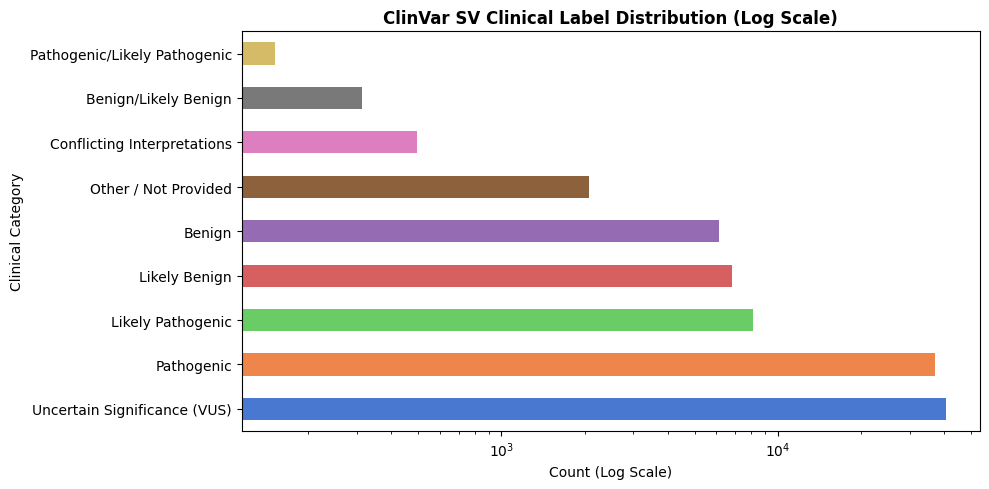

In [3]:
plt.figure(figsize=(10, 5))
label_counts.plot(kind="barh", color=sns.color_palette("muted"))
plt.xscale("log")
plt.title("ClinVar SV Clinical Label Distribution (Log Scale)", fontweight="bold")
plt.xlabel("Count (Log Scale)")
plt.ylabel("Clinical Category")
plt.tight_layout()
plt.show()


## 2. SV Type and Length Distributions

SV Types in ClinVar:
type
Deletion              30532
copy number gain      29737
copy number loss      28697
Duplication           11692
Indel                   970
Complex                  82
Inversion                65
Microsatellite           51
Translocation            49
Insertion                 8
Variation                 6
fusion                    1
Tandem duplication        1
Name: count, dtype: int64


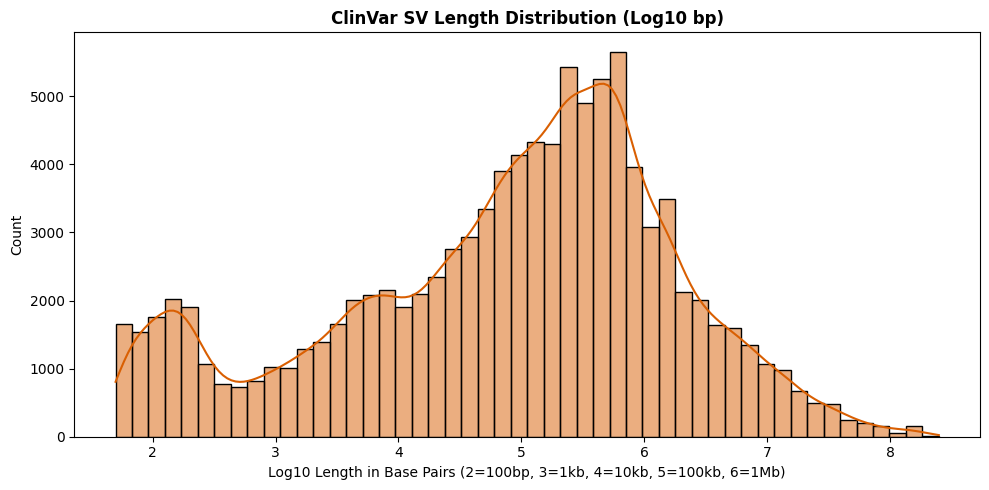

In [4]:
print("SV Types in ClinVar:")
print(df_cv["type"].value_counts())

plt.figure(figsize=(10, 5))
sns.histplot(np.log10(df_cv["length"].clip(lower=50)), bins=50, kde=True, color="#d95f02")
plt.title("ClinVar SV Length Distribution (Log10 bp)", fontweight="bold")
plt.xlabel("Log10 Length in Base Pairs (2=100bp, 3=1kb, 4=10kb, 5=100kb, 6=1Mb)")
plt.tight_layout()
plt.show()


## 3. Class Imbalance & VUS Recommendation
- **Pathogenic / Likely Pathogenic**: 45,277 (44.4%)
- **Benign / Likely Benign**: 13,306 (13.1%)
- **VUS (Uncertain Significance)**: 40,741 (40.0%)
- **Conflicting**: 494 (0.5%)

### Imbalance Ratio:
Between Pathogenic (45,277) and Benign (13,306), the class imbalance is **3.4 : 1**.  
This is moderate and manageable using class weighting, focal loss, or PR-AUC optimization.

### Recommendation on VUS & Conflicting:
- **Phase 1 (Primary Model)**: Train exclusively on high-confidence Pathogenic (1) vs Benign (0) labels to learn clean decision boundaries.
- **Phase 2 (Post-hoc Prioritization)**: Apply the trained model to the 40,741 VUS variants to generate continuous prioritization scores and SHAP explanations.
